### 9. Eigenvalues, Eigenvectors, and PCA Intuition

An eigenvector of a square matrix $A$ is a nonzero vector whose direction does not change when $A$ acts on it:
$$
Av = \lambda v
$$
The scalar $\lambda$ is the eigenvalue.

Eigenvalues and eigenvectors help reveal important directions in transformations and data.

In [1]:
import numpy as np

A = np.array([[2, 1], [1, 2]], dtype=float)
eigenvalues, eigenvectors = np.linalg.eig(A)

print("Eigenvalues:", eigenvalues)
print("Eigenvectors (columns):\\n", eigenvectors)

for i, value in enumerate(eigenvalues):
    v = eigenvectors[:, i]
    print("Check A @ v ≈ lambda * v:", np.allclose(A @ v, value * v))

Eigenvalues: [3.+0.j 1.+0.j]
Eigenvectors (columns):\n [[ 0.70710678+0.j -0.70710678+0.j]
 [ 0.70710678+0.j  0.70710678+0.j]]
Check A @ v ≈ lambda * v: True
Check A @ v ≈ lambda * v: True


### PCA intuition
Principal Component Analysis (PCA) finds directions that capture variance in data. In the classic covariance-matrix formulation, eigenvectors indicate principal directions and eigenvalues indicate variance along those directions.

PCA generally requires centering features; scaling may also be important when features use different units.

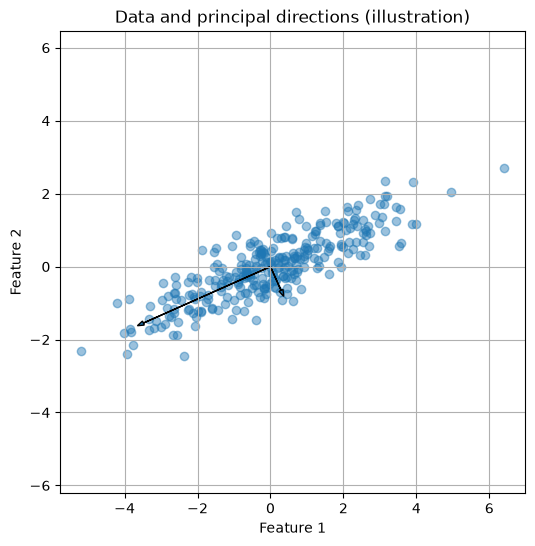

Variance captured by each direction: [3.98580881 0.19956028]
Explained variance ratios: [0.95231955 0.04768045]


In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
cov = np.array([[4.0, 1.7], [1.7, 1.0]])
data = rng.multivariate_normal([0, 0], cov, size=300)
centered = data - data.mean(axis=0)
covariance = np.cov(centered, rowvar=False)
values, vectors = np.linalg.eigh(covariance)
order = np.argsort(values)[::-1]
values, vectors = values[order], vectors[:, order]

plt.figure(figsize=(6, 6))
plt.scatter(centered[:, 0], centered[:, 1], alpha=0.45)
for i in range(2):
    direction = vectors[:, i] * np.sqrt(values[i]) * 2
    plt.arrow(0, 0, direction[0], direction[1], head_width=0.12, length_includes_head=True)
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.title("Data and principal directions (illustration)")
plt.axis("equal"); plt.grid(True); plt.show()
print("Variance captured by each direction:", values)
print("Explained variance ratios:", values / values.sum())

### Exercises
1. Verify an eigenpair by checking Av and λv.
2. What does a large eigenvalue mean in the covariance-matrix PCA setting?
3. Why should you think about centering and feature scaling before PCA?"